In [1]:
# ===========================================
#  Import Required Libraries
# ===========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
import os
print("Current working directory:", os.getcwd())


Current working directory: /home/rohitha/smai-2ass


In [3]:
file_path = "/home/rohitha/smai-2ass/Clustering_dataset.xlsx"
data = pd.read_excel(file_path, engine="openpyxl")   # requires openpyxl


# Preview the dataset
print("Dataset Shape:", data.shape)
data.head()


Dataset Shape: (200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19.0,15.0,39.0
1,2,Male,21.0,NaN,81.0
2,3,Female,20.0,16.0,6.0
3,4,Female,23.0,16.0,77.0
4,5,Female,31.0,17.0,40.0


In [4]:
# ===========================================
#  Preprocessing
# ===========================================
# Drop missing values (if any)
data = data.dropna()

# Select only numeric features (important for K-Means)
X = data.select_dtypes(include=np.number).values

print("Data prepared for clustering with shape:", X.shape)


Data prepared for clustering with shape: (178, 4)


In [5]:
# ===========================================
#  K-Means Clustering Class
# ===========================================

class KMeansCustom:
    """
    A custom implementation of the K-Means clustering algorithm.
    """

    def __init__(self, k: int, max_iters: int = 100, tol: float = 1e-4, random_state: int = 42):
        """
        Initialize the KMeans model.

        Parameters:
        - k (int): Number of clusters
        - max_iters (int): Maximum iterations
        - tol (float): Tolerance for convergence
        - random_state (int): Random seed for reproducibility
        """
        self.k = k
        self.max_iters = max_iters
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels = None

    def fit(self, X: np.ndarray):
        """
        Fit the KMeans model to the dataset.

        Parameters:
        - X (np.ndarray): Input data (n_samples, n_features)
        """
        np.random.seed(self.random_state)
        
        # Step 1: Randomly initialize centroids
        random_idx = np.random.choice(X.shape[0], self.k, replace=False)
        self.centroids = X[random_idx]

        for i in range(self.max_iters):
            # Step 2: Assign clusters
            distances = self._compute_distances(X)
            self.labels = np.argmin(distances, axis=1)

            # Step 3: Update centroids
            new_centroids = np.array([X[self.labels == j].mean(axis=0) for j in range(self.k)])

            # Step 4: Check for convergence
            if np.all(np.linalg.norm(self.centroids - new_centroids, axis=1) < self.tol):
                break

            self.centroids = new_centroids

    def predict(self, X: np.ndarray) -> np.ndarray:
        """
        Predict cluster labels for new data points.

        Parameters:
        - X (np.ndarray): Input data

        Returns:
        - labels (np.ndarray): Cluster assignments
        """
        distances = self._compute_distances(X)
        return np.argmin(distances, axis=1)

    def getCost(self, X: np.ndarray) -> float:
        """
        Compute Within-Cluster Sum of Squares (WCSS).

        Parameters:
        - X (np.ndarray): Input data

        Returns:
        - cost (float): WCSS score
        """
        distances = self._compute_distances(X)
        min_distances = np.min(distances, axis=1)
        return np.sum(min_distances ** 2)

    def _compute_distances(self, X: np.ndarray) -> np.ndarray:
        """Compute distances of all points to each centroid."""
        return np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)


In [6]:
# ===========================================
# Visualization Function
# ===========================================

def plot_clusters(X, labels, centroids, title="K-Means Clustering Result"):
    """
    Plot clustered data with centroids.
    
    Parameters:
    - X (np.ndarray): Data points
    - labels (np.ndarray): Cluster assignments
    - centroids (np.ndarray): Centroid positions
    - title (str): Title for the plot
    """
    plt.figure(figsize=(8,6))
    sns.scatterplot(x=X[:,0], y=X[:,1], hue=labels, palette="Set2", s=50)
    plt.scatter(centroids[:,0], centroids[:,1], c="red", marker="X", s=200, label="Centroids")
    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.legend()
    plt.show()


K-Means Cost (WCSS): 243563.95


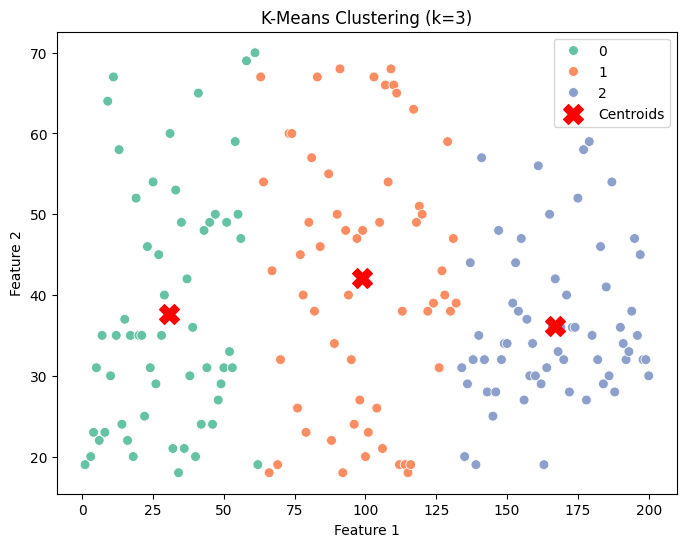

In [7]:
# ===========================================
#  Train K-Means Model
# ===========================================

k = 3  # Change based on dataset
kmeans = KMeansCustom(k=k)
kmeans.fit(X)

labels = kmeans.labels
cost = kmeans.getCost(X)

print(f"K-Means Cost (WCSS): {cost:.2f}")

# Plot results (works best if dataset has 2 features)
if X.shape[1] >= 2:
    plot_clusters(X, labels, kmeans.centroids, title=f"K-Means Clustering (k={k})")
else:
    print("Dataset has less than 2 features. Skipping plot.")


In [8]:
# ===========================================
#  Elbow Method: Compute WCSS for different k
# ===========================================

def compute_wcss_range(X, max_k=10):
    """
    Compute WCSS values for K=1 to max_k using KMeansCustom.

    Parameters:
    - X (np.ndarray): Dataset
    - max_k (int): Maximum number of clusters to test

    Returns:
    - wcss (list): WCSS values for each K
    """
    wcss = []
    for k in range(1, max_k+1):
        model = KMeansCustom(k=k)
        model.fit(X)
        cost = model.getCost(X)
        wcss.append(cost)
        print(f"K={k}, WCSS={cost:.2f}")
    return wcss

# Example: Compute WCSS for k=1..10
wcss_values = compute_wcss_range(X, max_k=10)


K=1, WCSS=900484.42
K=2, WCSS=354089.35
K=3, WCSS=243563.95
K=4, WCSS=208260.37
K=5, WCSS=173519.25
K=6, WCSS=168801.40
K=7, WCSS=109312.26
K=8, WCSS=91350.03
K=9, WCSS=74079.16
K=10, WCSS=69452.77


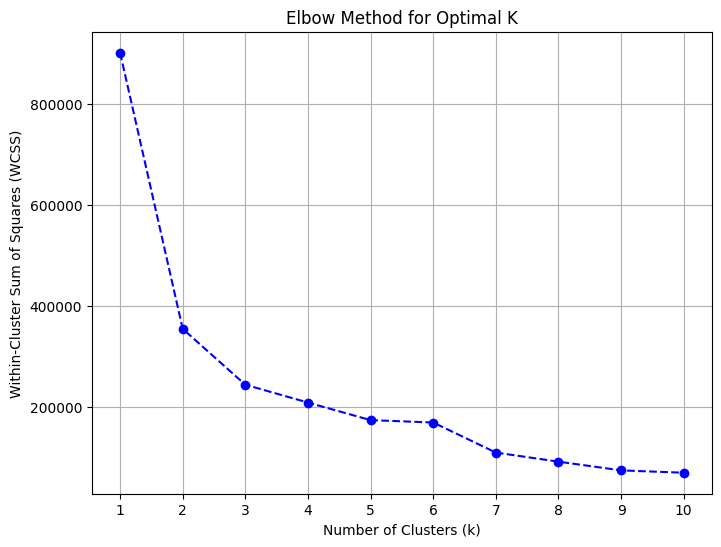

In [9]:
# ===========================================
# Elbow Method Visualization
# ===========================================

def plot_elbow(wcss_values, max_k=10):
    """
    Plot the elbow curve of WCSS vs number of clusters.
    
    Parameters:
    - wcss_values (list): WCSS values for each K
    - max_k (int): Maximum number of clusters tested
    """
    plt.figure(figsize=(8,6))
    plt.plot(range(1, max_k+1), wcss_values, marker="o", linestyle="--", color="b")
    plt.title("Elbow Method for Optimal K")
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
    plt.xticks(range(1, max_k+1))
    plt.grid(True)
    plt.show()

# Example: Plot elbow curve
plot_elbow(wcss_values, max_k=10)


###  Elbow Method Observation
From the Elbow curve, the optimal value of K is chosen at the "bend" or "elbow point", 
where adding more clusters does not significantly reduce WCSS.  
( Write your observation here after seeing the plot. Example: The elbow is at K=3, so the optimal number of clusters is 3.)


In [10]:
# ===========================================
#  Silhouette Method: Compute silhouette scores
# ===========================================
from sklearn.metrics import silhouette_score

def compute_silhouette_range(X, max_k=10):
    """
    Compute silhouette scores for K=2 to max_k using KMeansCustom.
    (Silhouette is not defined for K=1)

    Parameters:
    - X (np.ndarray): Dataset
    - max_k (int): Maximum number of clusters to test

    Returns:
    - scores (list): Silhouette scores for each K
    """
    scores = []
    for k in range(2, max_k+1):
        model = KMeansCustom(k=k)
        model.fit(X)
        labels = model.labels
        score = silhouette_score(X, labels)
        scores.append(score)
        print(f"K={k}, Silhouette Score={score:.3f}")
    return scores

# Example: Compute silhouette scores for k=2..10
silhouette_scores = compute_silhouette_range(X, max_k=10)


K=2, Silhouette Score=0.480
K=3, Silhouette Score=0.384
K=4, Silhouette Score=0.374
K=5, Silhouette Score=0.338
K=6, Silhouette Score=0.313
K=7, Silhouette Score=0.390
K=8, Silhouette Score=0.378
K=9, Silhouette Score=0.378
K=10, Silhouette Score=0.365


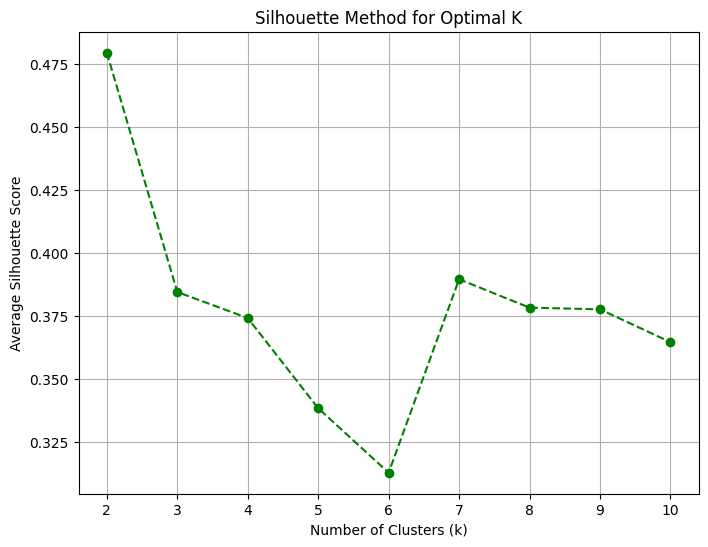

In [11]:
# ===========================================
# Silhouette Method Visualization
# ===========================================

def plot_silhouette(silhouette_scores, max_k=10):
    """
    Plot silhouette scores vs number of clusters.

    Parameters:
    - silhouette_scores (list): Scores for K=2..max_k
    - max_k (int): Maximum number of clusters tested
    """
    plt.figure(figsize=(8,6))
    plt.plot(range(2, max_k+1), silhouette_scores, marker="o", linestyle="--", color="g")
    plt.title("Silhouette Method for Optimal K")
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Average Silhouette Score")
    plt.xticks(range(2, max_k+1))
    plt.grid(True)
    plt.show()

# Example: Plot silhouette scores
plot_silhouette(silhouette_scores, max_k=10)


###  Silhouette Method Observation
The optimal number of clusters is the value of K where the silhouette score is maximized.  

 Write your observation here after checking the plot.  
For example:  
- The highest silhouette score occurs at K=3.  
- This suggests the dataset is best represented by 3 clusters.  
- The clusters at this K are well-separated and compact.  
